In [59]:
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.datatypes import ElectricalSignal, OpticalSignal
from optical_communication_system.utils import dbm_to_w, from_db
from optical_communication_system.plot import *

In [26]:
Component.trace_debug_enabled_by_default = True

data_rate = 10e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = 2e-3 # Watts

lpf = BandPassFilter(min_frequency=0.0, max_frequency=1 * data_rate, name="lpf")

bits_per_symbol = 2

channel_osnr = 30.0

channel = Composition([
    OpticalAWGN(relative_db=-channel_osnr, name="channel_noise"),
    OpticalFiber(
        attenuation=0.22,
        length=40.0,
        chromatic_dispersion=17.0,
        eff_non_linear_coeff=1.76,
        central_frequency=central_frequency,
        step_count=1000,
        name="fiber"
    )
], name="channel")

input_laser = Laser(power=input_power, name="laser")

photodiode = Composition([Photodiode(), Quantizer(step=1e-4), lpf])

transmitter = Composition([
    PAMEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=PAMSymbolEncoder(
            bits_per_symbol=bits_per_symbol,
            adjust_for_mzm=True,
            name="pam_symbol_encoder"
        )
    ),
    Composition([lpf], name="encoder_output"),
    MachZehnderModulator(carrier_source=input_laser, name="modulator")
], name="transmitter")

receiver = Composition([
    Composition([photodiode], name="receiver_output"),
    ElectricalGain(gain=1.0),
    PAMDecoder(
        data_rate=data_rate,
        symbol_decoder=PAMSymbolDecoder(
            bits_per_symbol=bits_per_symbol,
            name="pam_symbol_decoder"
        ),
        name="decoder_output"
    )
])

system = Composition([transmitter, channel, receiver])
channel_loss_estimator = ChannelLossEstimator(
    laser=input_laser,
    photodiode=photodiode,
    channel=channel,
    sampling_rate=1e9
)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
ber_tester = BERTester(system)

In [116]:
input_signal = tf.constant([[1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1]], dtype=tf.int32)
#input_signal = rng.uniform((1, 512), 0, 2, dtype=tf.int32)

data_rate = 10e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = dbm_to_w(3.0) # Watts

bits_per_symbol = 2
channel_osnr = 30.0
cutoff_frequency = 2.0 * data_rate

system_params = dict(
    laser__power=tf.constant(input_power),
    fiber__step_count=tf.constant(1),
    fiber__length=tf.constant(20.0),
    fiber__eff_non_linear_coeff=tf.constant(1.76),
    fiber__chromatic_dispersion=tf.constant(17.0 * -4),
    pam_encoder__data_rate=tf.constant(data_rate),
    pam_encoder__sampling_rate=tf.constant(sampling_rate),
    decoder_output__data_rate=tf.constant(data_rate),
    pam_symbol_encoder__bits_per_symbol=tf.constant(bits_per_symbol),
    pam_symbol_decoder__bits_per_symbol=tf.constant(bits_per_symbol),
    channel_noise__relative_db=tf.constant(-channel_osnr),
    lpf__max_frequency=tf.constant(cutoff_frequency),
    quantizer__step=tf.constant(1e-6),
    batch_size=tf.shape(input_signal)[0],
    parameter_dims=tf.constant(1),
    photodiode__sensitivity=dbm_to_w(-20.0),
    photodiode__maximum_power=dbm_to_w(3.0)
)

estimated_channel_loss = channel_loss_estimator(1000e-9, **system_params)[0]

symbol_scale = input_power / estimated_channel_loss
system_params["electrical_gain__gain"] = 1.0 / symbol_scale

%time system.trace(input_signal, **system_params)

Calling Composition(name='composition') with args tf.Tensor(shape=[ 1 16], dtype=tf.int32)
|---Calling Composition(name='transmitter') with args tf.Tensor(shape=[ 1 16], dtype=tf.int32)
|---|---Calling PAMEncoder(name='pam_encoder') with args tf.Tensor(shape=[ 1 16], dtype=tf.int32)
|---|---|---Calling PAMSymbolEncoder(name='pam_symbol_encoder') with args tf.Tensor(shape=[ 1 16], dtype=tf.int32)
|---|---|---|---Return tf.Tensor(shape=[1 1 8], dtype=tf.float32)
|---|---|---Return ElectricalSignal[  1   1 160]
|---|---Calling Composition(name='encoder_output') with args ElectricalSignal[  1   1 160]
|---|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal[  1   1 160]
|---|---|---|---Return ElectricalSignal[  1   1 160]
|---|---|---Return ElectricalSignal[  1   1 160]
|---|---Calling MachZehnderModulator(name='modulator') with args ElectricalSignal[  1   1 160]
|---|---Calling Laser(name='laser') with args Timing
|---|---|---Return OpticalSignal[  1   1 160]
|---|---|---

<tf.Tensor: shape=(1, 1, 16), dtype=int32, numpy=array([[[1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0]]], dtype=int32)>

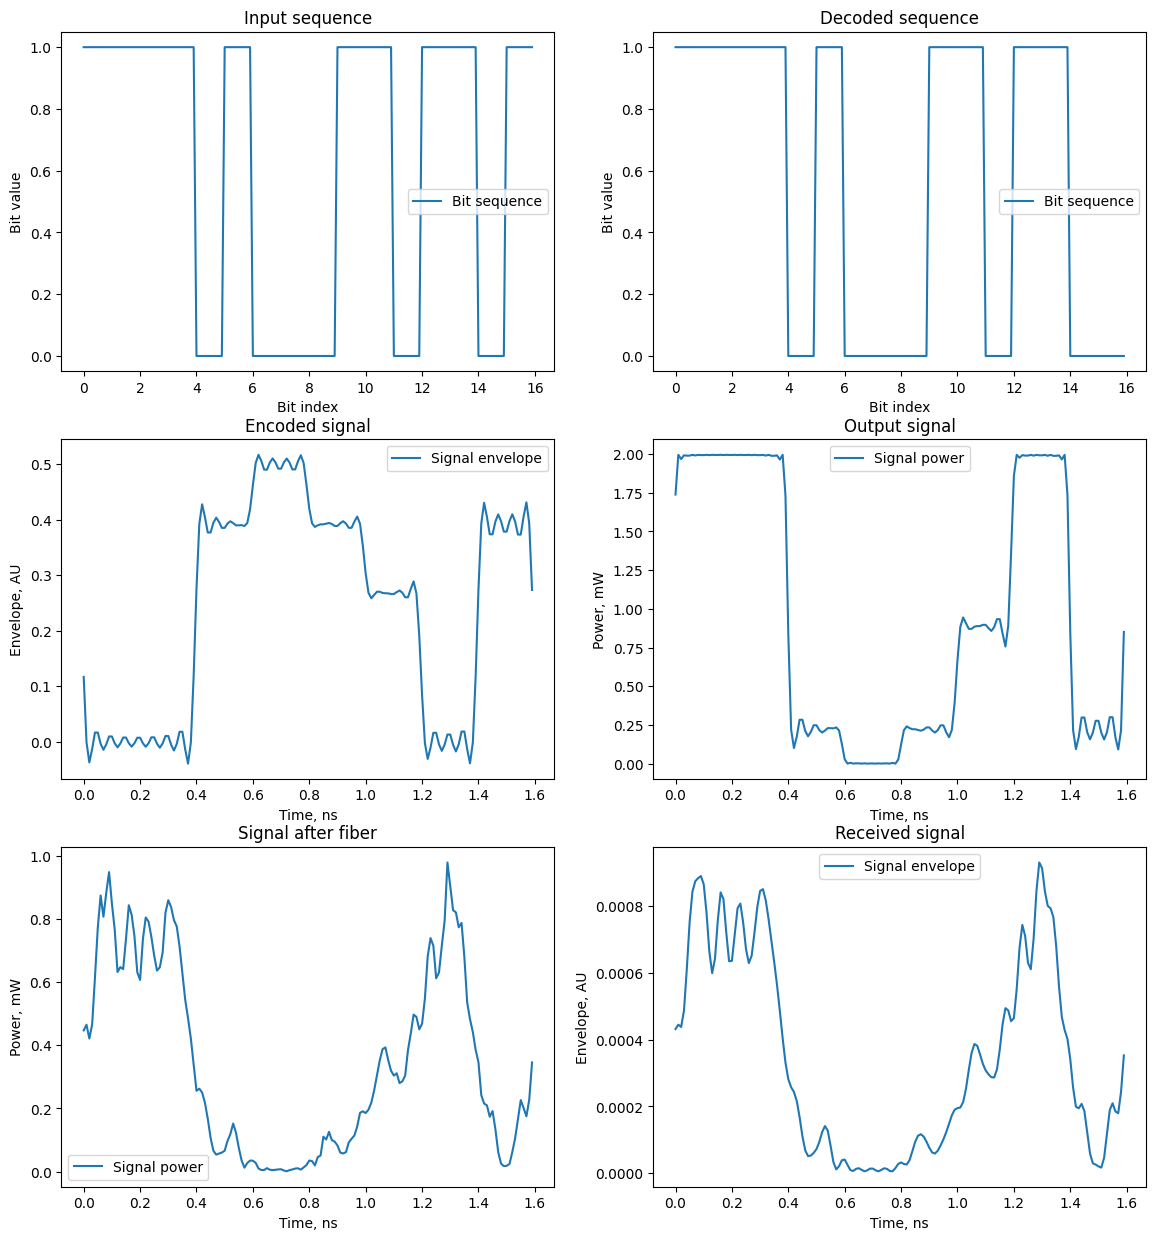

In [117]:
fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax, 0)
plot_envelope(system.find_child("encoder_output").output, encoded_ax)
plot_power(system.find_child("modulator").output, output_ax)
plot_power(system.find_child("channel").output, fiber_ax)

plot_envelope(system.find_child("receiver_output").output, received_ax)

plot_bitseq(system.output, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

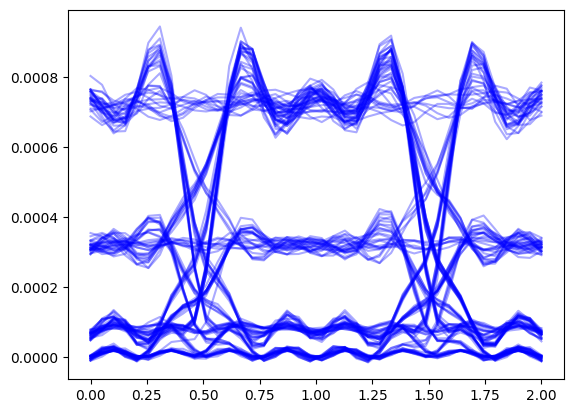

In [106]:
signal = system.find_child("receiver_output").output
plot_eye_diagram(signal, symbol_rate=data_rate / bits_per_symbol, color="blue", alpha=0.333)

In [107]:
%time ber_tester(tf.constant(128), **system_params)

CPU times: user 83.3 ms, sys: 156 μs, total: 83.5 ms
Wall time: 68.8 ms


<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>